<a href="https://colab.research.google.com/github/AnushGoel/cpu-diffusion-toolkit/blob/main/AAI6640_Assignment2_CPU_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
FAST_MODE = True     # True = small and quick, False = report-quality output

# Thread env vars must be set BEFORE torch is imported, or they are ignored.
import os
NCPU = os.cpu_count() or 2
os.environ["OMP_NUM_THREADS"] = str(NCPU)
os.environ["MKL_NUM_THREADS"] = str(NCPU)

print(f"{NCPU} logical CPUs")

24 logical CPUs


In [2]:
!pip install -q --upgrade diffusers transformers accelerate safetensors huggingface_hub
!pip install -q --upgrade gradio imageio imageio-ffmpeg
print("installs complete")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 72.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.1/147.1 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.4/130.4 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.1 MB/s eta 0:00:00
installs complete


In [3]:
import os, gc, time, platform, psutil, torch
from contextlib import contextmanager

# Self-healing: if you jumped here without running the cell above, or restarted
# the session, re-derive NCPU instead of raising NameError.
NCPU = globals().get("NCPU") or os.cpu_count() or 2
FAST_MODE = globals().get("FAST_MODE", True)

torch.set_num_threads(NCPU)
torch.set_grad_enabled(False)          # nothing here is training; saves memory everywhere

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# fp16 has no fast CPU kernels for convolution in PyTorch - on CPU it is SLOWER
# than fp32, not faster. So dtype follows the device.
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

HW = (torch.cuda.get_device_name(0) if DEVICE == "cuda"
      else f"CPU, {NCPU} threads ({psutil.virtual_memory().total / 1e9:.1f} GB RAM)")

TIMINGS = {}

@contextmanager
def timer(label):
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    yield
    if DEVICE == "cuda":
        torch.cuda.synchronize()       # GPU work is async; without this you time the launch
    dt = time.perf_counter() - t0
    TIMINGS[label] = dt
    print(f"[TIME] {label}: {dt:.2f} s")

def ram():
    v = psutil.virtual_memory()
    return f"RAM {v.used / 1e9:.1f} / {v.total / 1e9:.1f} GB"

def drop(*names):
    for n in names:
        globals().pop(n, None)
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

print("Device :", DEVICE)
print("Hardware:", HW)
print("dtype  :", DTYPE)
print("Torch  :", torch.__version__)
print("Python :", platform.python_version())
print(ram())

Device : cpu
Hardware: CPU, 24 threads (50.5 GB RAM)
dtype  : torch.float32
Torch  : 2.14.1+cpu
Python : 3.13.16
RAM 3.7 / 50.5 GB


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


### The four CPU optimisations used throughout

Each one is worth a sentence in the report, because together they are the difference between "runs" and "does not finish".

1. **Step count over model size.** Both diffusion models here are *distilled*: they were trained to reach a usable image in 1-4 denoising steps instead of 25-50. On a GPU that is a nice-to-have. On a CPU it is the whole game, because runtime is close to linear in step count.
2. **A tiny VAE.** `madebyollin/taesd` is a distilled stand-in for Stable Diffusion's variational autoencoder. The real VAE decoder is one of the most expensive parts of the pipeline on CPU - decoding eight video frames with it takes longer than denoising them. TAESD is roughly three orders of magnitude cheaper and the difference is barely visible at these resolutions.
3. **No classifier-free guidance.** `guidance_scale=1.0` (or `0.0` for Turbo) means one UNet forward pass per step instead of two. Both distilled models were trained without CFG, so this costs nothing in quality. It halves the work.
4. **fp32, not fp16.** Counter-intuitive, but PyTorch has no fast fp16 convolution kernels on CPU. Casting down makes it slower. We only use fp16 if a GPU is present.

---
# Task 1 - Text to Image: `stabilityai/sd-turbo`

**What it is.** SD-Turbo is a distilled version of Stable Diffusion 2.1. Stability trained it with Adversarial Diffusion Distillation (ADD), which combines an adversarial loss against a discriminator with a score-distillation loss against the frozen SD 2.1 teacher. The student learns to jump most of the way down the denoising trajectory in one move, so a **single** network evaluation produces a usable 512x512 image.

**Architecture.** An 865M-parameter UNet, an OpenCLIP ViT-H text encoder, and the SD 2.1 VAE (which we swap for TAESD). Roughly a third the size of SDXL-Turbo, which is why it is the one that fits here.

**Two quirks the code has to respect:**
- `guidance_scale` must be `0.0`. Turbo was distilled without classifier-free guidance, so a non-zero value produces washed-out output.
- `negative_prompt` is ignored for the same reason.

**License.** `sai-nc-community`, non-commercial research. Fine for coursework, and the repo is public with no access gate.

**Screenshot for the report:** the model card page, plus the "Use this model -> Diffusers" snippet panel.

In [4]:
from diffusers import AutoPipelineForText2Image, AutoencoderTiny

T2I_ID   = "stabilityai/sd-turbo"
TINY_VAE = "madebyollin/taesd"

def load_pipe(cls, repo, **kw):
    # The fp16 files are half the download; we upcast to fp32 on load for CPU speed.
    # Not every repo publishes an fp16 variant, hence the fallback.
    try:
        return cls.from_pretrained(repo, torch_dtype=DTYPE, variant="fp16", **kw)
    except Exception:
        return cls.from_pretrained(repo, torch_dtype=DTYPE, **kw)

drop()
with timer("Task 1 | model load"):
    t2i = load_pipe(AutoPipelineForText2Image, T2I_ID,
                    safety_checker=None, requires_safety_checker=False)
    t2i.vae = AutoencoderTiny.from_pretrained(TINY_VAE, torch_dtype=DTYPE)
    t2i = t2i.to(DEVICE)
    t2i.enable_attention_slicing()      # lower peak RAM, negligible cost on CPU

print("Loaded:", T2I_ID, "|", ram())

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/597 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 9.79MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

[TIME] Task 1 | model load: 29.20 s
Loaded: stabilityai/sd-turbo | RAM 9.3 / 50.5 GB


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

[TIME] Task 1 | inference #1: 10.69 s


  0%|          | 0/1 [00:00<?, ?it/s]

[TIME] Task 1 | inference #2: 10.64 s


  0%|          | 0/1 [00:00<?, ?it/s]

[TIME] Task 1 | inference #3: 17.44 s

Average: 12.93 s per 384x384 image
Hardware: CPU, 24 threads (50.5 GB RAM) | RAM 9.3 / 50.5 GB


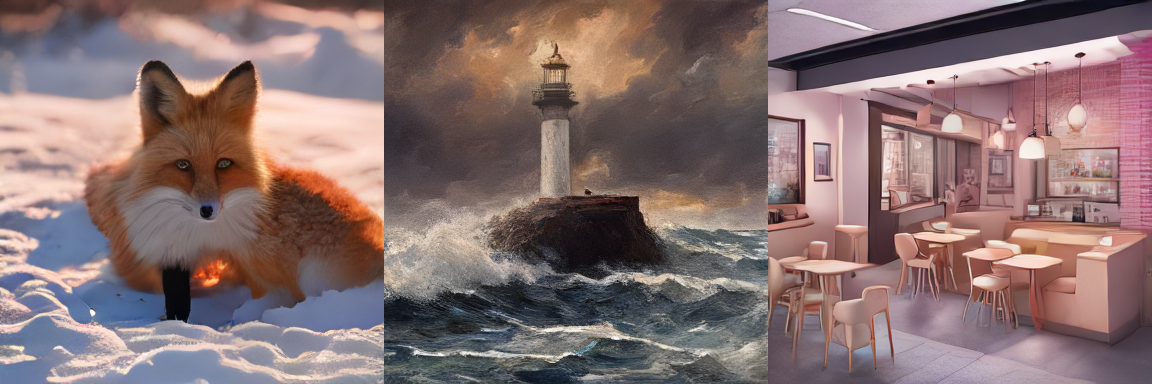

In [5]:
from diffusers.utils import make_image_grid

SIZE_T2I = 384 if FAST_MODE else 512

PROMPTS = [
    "a cinematic photograph of a red fox sitting in deep snow at sunrise",
    "an oil painting of a lighthouse in a storm, thick visible brush strokes",
    "an isometric 3D render of a cosy coffee shop, pastel colours, soft lighting",
]

# Warm-up: the first call allocates buffers and picks convolution algorithms,
# so it is always slower. Timing it would overstate the real per-image cost.
_ = t2i(prompt="warm up", num_inference_steps=1, guidance_scale=0.0,
        height=SIZE_T2I, width=SIZE_T2I).images[0]

images, per_image = [], []
for i, prompt in enumerate(PROMPTS, 1):
    label = f"Task 1 | inference #{i}"
    with timer(label):
        img = t2i(
            prompt=prompt,
            num_inference_steps=1,       # SD-Turbo is a one-step model
            guidance_scale=0.0,          # MUST be 0.0
            height=SIZE_T2I, width=SIZE_T2I,
        ).images[0]
    img.save(f"task1_{i}.png")
    images.append(img)
    per_image.append(TIMINGS[label])

print(f"\nAverage: {sum(per_image) / len(per_image):.2f} s per {SIZE_T2I}x{SIZE_T2I} image")
print("Hardware:", HW, "|", ram())
make_image_grid(images, rows=1, cols=len(images))

### Optional: step count against wall-clock time

A good extra figure. It shows the near-linear relationship between steps and CPU runtime, which is exactly the reason a distilled model was chosen.

  0%|          | 0/1 [00:00<?, ?it/s]

[TIME] Task 1 | 1-step: 10.50 s


  0%|          | 0/2 [00:00<?, ?it/s]

[TIME] Task 1 | 2-step: 26.81 s


  0%|          | 0/4 [00:00<?, ?it/s]

[TIME] Task 1 | 4-step: 37.20 s
1 step(s):  10.50 s
2 step(s):  26.81 s
4 step(s):  37.20 s


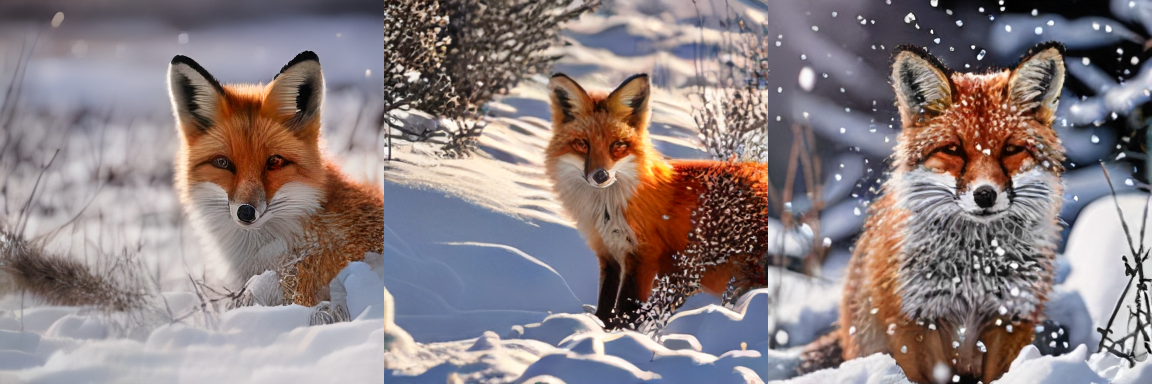

In [6]:
step_rows = []
for steps in [1, 2, 4]:
    label = f"Task 1 | {steps}-step"
    with timer(label):
        im = t2i(prompt=PROMPTS[0], num_inference_steps=steps, guidance_scale=0.0,
                 height=SIZE_T2I, width=SIZE_T2I).images[0]
    step_rows.append((steps, TIMINGS[label], im))

for steps, dt, _ in step_rows:
    print(f"{steps} step(s): {dt:6.2f} s")

make_image_grid([im for _, _, im in step_rows], rows=1, cols=len(step_rows))

In [7]:
drop("t2i")
print("Task 1 pipeline unloaded |", ram())

Task 1 pipeline unloaded | RAM 6.8 / 50.5 GB


---
# Task 2 - Image to Video: `ByteDance/AnimateDiff-Lightning`

**What AnimateDiff is.** Rather than train a video model from scratch, AnimateDiff inserts *motion modules* - temporal self-attention layers - between the existing spatial layers of a frozen Stable Diffusion UNet. The motion module is trained on video while the image model stays untouched, so any SD 1.5 checkpoint can be turned into a video model by plugging the adapter in. In diffusers this is a `MotionAdapter` combined with a normal SD pipeline to form a `UNetMotionModel`.

**What Lightning adds.** ByteDance distilled the AnimateDiff SD 1.5 v2 motion module down to 1, 2, 4 and 8 step variants using cross-model diffusion distillation. The 4-step checkpoint used here is the reason this task is possible at all on a CPU: original AnimateDiff needs around 25 steps with classifier-free guidance, which is 50 UNet passes per frame. This needs 3-4 passes, with no CFG.

**How the image conditioning works, and be ready to explain this.** AnimateDiff is natively text-to-video. To drive it from an image we use `AnimateDiffVideoToVideoPipeline` and hand it the still repeated N times as the input "video", with `strength < 1.0`. The pipeline noises that clip partway and denoises from there, so the output keeps the composition, colours and subject of your image while the temporal attention layers introduce coherent motion. It is the standard "animate a still" recipe and it is genuinely image-conditioned - set `strength=1.0` and the input image stops mattering, which is a good thing to demonstrate.

Two knobs to tune:
- **`strength` too low** - barely moves, nearly a static clip.
- **`strength` too high** - lively, but drifts away from your input image.
- 0.5 to 0.7 is usually the sweet spot.

**Licenses.** Motion adapter `creativeml-openrail-m`, base SD 1.5 `creativeml-openrail-m`. Both public, neither gated.

> This cell downloads about 3 GB. It is the slow one.

In [8]:
from diffusers import (AnimateDiffVideoToVideoPipeline, MotionAdapter,
                       EulerDiscreteScheduler, AutoencoderTiny)
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

BASE_ID      = "stable-diffusion-v1-5/stable-diffusion-v1-5"
ADAPTER_REPO = "ByteDance/AnimateDiff-Lightning"
ADAPTER_STEP = 4                              # options: 1, 2, 4, 8
CKPT = f"animatediff_lightning_{ADAPTER_STEP}step_diffusers.safetensors"

drop()
with timer("Task 2 | model load"):
    adapter = MotionAdapter().to(DEVICE, DTYPE)
    adapter.load_state_dict(load_file(hf_hub_download(ADAPTER_REPO, CKPT), device="cpu"))

    # AnimateDiff pipelines have no safety_checker slot, and diffusers simply will
    # not fetch the component, so SD 1.5's 1.2 GB checker is never downloaded.
    i2v = load_pipe(AnimateDiffVideoToVideoPipeline, BASE_ID,
                    motion_adapter=adapter)

    # Lightning was distilled against this exact scheduler configuration.
    i2v.scheduler = EulerDiscreteScheduler.from_config(
        i2v.scheduler.config, timestep_spacing="trailing", beta_schedule="linear")

    i2v.vae = AutoencoderTiny.from_pretrained("madebyollin/taesd", torch_dtype=DTYPE)
    i2v = i2v.to(DEVICE)
    i2v.enable_attention_slicing()

print("Loaded adapter + base |", ram())

There are modules in MotionAdapter that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


animatediff_lightning_4step_diffusers.sa(…): reconstructing file:   0%|          |  0.00B /  908MB            

animatediff_lightning_4step_diffusers.sa(…): downloading bytes:           |  0.00B            

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNetMotionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


[TIME] Task 2 | model load: 51.18 s
Loaded adapter + base | RAM 14.7 / 50.5 GB


  0%|          | 0/3 [00:00<?, ?it/s]

[TIME] Task 2 | inference: 301.09 s
8 frames at 256x256 | CPU, 24 threads (50.5 GB RAM) | RAM 15.1 / 50.5 GB


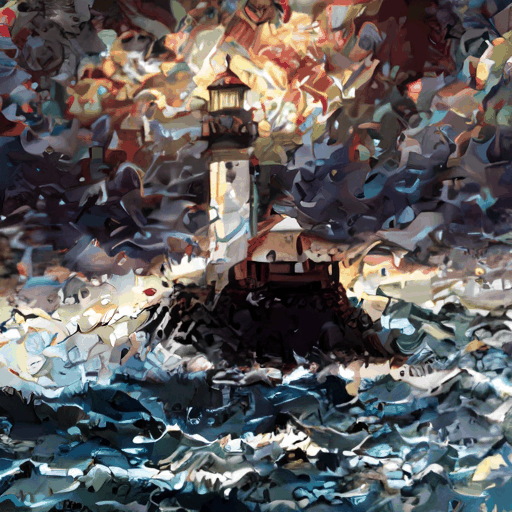

In [9]:
from diffusers.utils import export_to_video, export_to_gif, load_image

SIZE_I2V   = 256 if FAST_MODE else 320      # must be divisible by 8
NUM_FRAMES = 8   if FAST_MODE else 16
STEPS_I2V  = 6
STRENGTH   = 0.6

# Condition on the lighthouse generated in Task 1.
# Swap for anything: load_image("https://...") or load_image("/content/mine.png")
init_image = load_image("task1_2.png").convert("RGB").resize((SIZE_I2V, SIZE_I2V))

I2V_PROMPT = ("a lighthouse in a storm, waves crashing against the rocks, "
              "clouds drifting across the sky, cinematic")

with timer("Task 2 | inference"):
    frames = i2v(
        video=[init_image] * NUM_FRAMES,     # the still, repeated = the input clip
        prompt=I2V_PROMPT,
        num_inference_steps=STEPS_I2V,
        strength=STRENGTH,                   # effective steps = steps * strength
        guidance_scale=1.0,                  # Lightning is distilled without CFG
        generator=torch.Generator("cpu").manual_seed(42),
    ).frames[0]

export_to_video(frames, "task2_output.mp4", fps=8)
export_to_gif(frames, "task2_output.gif")    # GIF embeds cleanly in a Word report

print(f"{len(frames)} frames at {SIZE_I2V}x{SIZE_I2V} |", HW, "|", ram())

from IPython.display import Image as IPyImage, display
display(IPyImage(filename="task2_output.gif"))

left = input still, right = generated frames


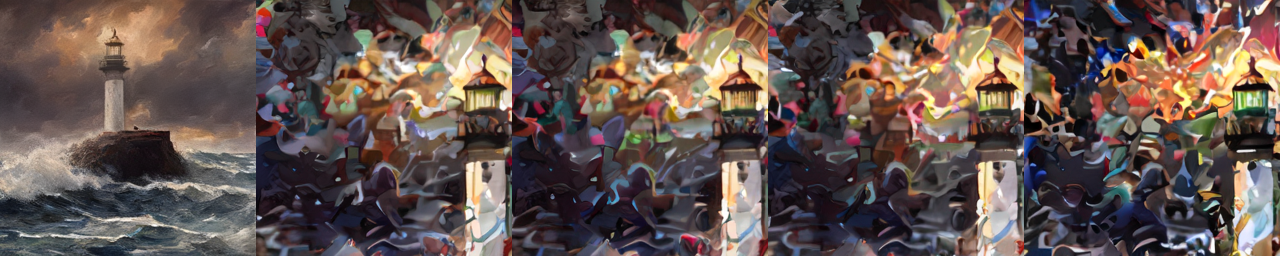

In [10]:
# Side-by-side: the conditioning image next to four frames of the result.
# This single figure proves image-to-video better than the video file does.
from diffusers.utils import make_image_grid

picks = [frames[i] for i in range(0, len(frames), max(1, len(frames) // 4))][:4]
grid = make_image_grid([init_image] + picks, rows=1, cols=len(picks) + 1)
grid.save("task2_comparison.png")
print("left = input still, right = generated frames")
grid

In [11]:
drop("i2v", "adapter")
print("Task 2 pipeline unloaded |", ram())

Task 2 pipeline unloaded | RAM 12.0 / 50.5 GB


---
# Task 3 - Text Classification: `SamLowe/roberta-base-go_emotions`

**What it is.** A `roberta-base` encoder (125M parameters, 12 layers, 768 hidden) fine-tuned on Google's **GoEmotions** dataset: 58k Reddit comments hand-labelled across 27 emotion categories plus `neutral`.

**Why it is more interesting than a sentiment model.** This is **multi-label**, not multi-class. The classification head applies a sigmoid to each of the 28 logits independently rather than a softmax across them, so the scores do not sum to 1 and one sentence can legitimately be *admiration* and *gratitude* and *joy* at once. That is why the code passes `top_k=None`, which returns every label with its own probability.

**Thresholding.** Because the labels are independent there is no argmax to take. You pick an operating threshold, typically 0.3-0.5, and everything above it is a predicted label. Lower it for recall, raise it for precision. The Gradio tab exposes this as a slider so you can show the effect in a screenshot.

**Why it is the easy task here.** 125M parameters, one forward pass, no iterative denoising. This runs in well under a second on 2 vCPU, which makes for a nice contrast with the two diffusion models in your timing discussion.

**License.** MIT. Public, not gated.

**Screenshot for the report:** the model card, plus the inference widget on the right of the page with one of your own sentences in it.

In [12]:
from transformers import pipeline as hf_pipeline

CLS_ID = "SamLowe/roberta-base-go_emotions"

with timer("Task 3 | model load"):
    clf = hf_pipeline(
        "text-classification",
        model=CLS_ID,
        top_k=None,                           # all 28 labels, not just the winner
        device=0 if DEVICE == "cuda" else -1,
    )

print("Loaded:", CLS_ID, "| labels:", len(clf.model.config.id2label), "|", ram())

config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

[TIME] Task 3 | model load: 8.09 s
Loaded: SamLowe/roberta-base-go_emotions | labels: 28 | RAM 12.2 / 50.5 GB


In [13]:
import pandas as pd

SAMPLES = [
    "I cannot believe we finally shipped this. I am so proud of the whole team.",
    "The flight was delayed four hours and nobody bothered to tell us anything.",
    "Hmm, I am not sure that is how the loss function is supposed to behave.",
    "Thank you so much, this genuinely made my week.",
    "I am dreading the exam on Friday and I have barely started revising.",
]

_ = clf("warm up")

rows = []
for i, text in enumerate(SAMPLES, 1):
    label = f"Task 3 | inference #{i}"
    with timer(label):
        scores = clf(text)[0]
    top3 = sorted(scores, key=lambda d: d["score"], reverse=True)[:3]
    rows.append({
        "text": text[:50] + ("..." if len(text) > 50 else ""),
        "1st": f"{top3[0]['label']} ({top3[0]['score']:.3f})",
        "2nd": f"{top3[1]['label']} ({top3[1]['score']:.3f})",
        "3rd": f"{top3[2]['label']} ({top3[2]['score']:.3f})",
        "ms": round(TIMINGS[label] * 1000, 1),
    })

pd.DataFrame(rows)

[TIME] Task 3 | inference #1: 0.39 s
[TIME] Task 3 | inference #2: 0.31 s
[TIME] Task 3 | inference #3: 0.70 s
[TIME] Task 3 | inference #4: 0.30 s
[TIME] Task 3 | inference #5: 0.30 s


,text,1st,2nd,3rd,ms
0,I cannot believe we finally shipped this. I am...,admiration (0.343),pride (0.310),excitement (0.110),391.6
1,The flight was delayed four hours and nobody b...,disappointment (0.499),neutral (0.289),annoyance (0.262),309.0
2,"Hmm, I am not sure that is how the loss functi...",confusion (0.909),neutral (0.092),approval (0.037),701.1
3,"Thank you so much, this genuinely made my week.",gratitude (0.991),approval (0.014),joy (0.014),296.6
4,I am dreading the exam on Friday and I have ba...,fear (0.228),nervousness (0.128),disappointment (0.120),301.2


In [14]:
# Batched throughput - the fairer number to quote, since a single short sentence
# is dominated by tokenisation and Python overhead rather than by the model.
with timer("Task 3 | batch of 5"):
    _ = clf(SAMPLES)

per = TIMINGS["Task 3 | batch of 5"] / len(SAMPLES) * 1000
print(f"{per:.1f} ms per sentence when batched, on {HW}")

[TIME] Task 3 | batch of 5: 1.79 s
358.5 ms per sentence when batched, on CPU, 24 threads (50.5 GB RAM)


---
## Timing summary

This table is the evidence for the "calculate the time for running the model on your device" requirement. Screenshot it together with the hardware line printed above it - a duration without the hardware that produced it is not a measurement.

In [15]:
import pandas as pd

summary = pd.DataFrame([{"step": k, "seconds": round(v, 3)} for k, v in TIMINGS.items()])
summary["minutes"] = (summary["seconds"] / 60).round(2)

print("Hardware :", HW)
print("Torch    :", torch.__version__)
print("Precision:", DTYPE)
print("FAST_MODE:", FAST_MODE)
summary

Hardware : CPU, 24 threads (50.5 GB RAM)
Torch    : 2.14.1+cpu
Precision: torch.float32
FAST_MODE: True


,step,seconds,minutes
0,Task 1 | model load,29.198,0.49
1,Task 1 | inference #1,10.695,0.18
2,Task 1 | inference #2,10.644,0.18
3,Task 1 | inference #3,17.445,0.29
4,Task 1 | 1-step,10.500,0.18
5,Task 1 | 2-step,26.811,0.45
6,Task 1 | 4-step,37.196,0.62
7,Task 2 | model load,51.184,0.85
8,Task 2 | inference,301.092,5.02
9,Task 3 | model load,8.087,0.13


In [17]:
summary.to_csv("timings.csv", index=False)

try:
    print(summary.to_markdown(index=False))     # paste straight into the report
except ImportError:
    print("\n[INFO] 'tabulate' package not found. Showing default text alignment below.\n(To get a true markdown table, you can run: !pip install tabulate)\n")
    print(summary.to_string(index=False))


[INFO] 'tabulate' package not found. Showing default text alignment below.
(To get a true markdown table, you can run: !pip install tabulate)

                 step  seconds  minutes
  Task 1 | model load   29.198     0.49
Task 1 | inference #1   10.695     0.18
Task 1 | inference #2   10.644     0.18
Task 1 | inference #3   17.445     0.29
      Task 1 | 1-step   10.500     0.18
      Task 1 | 2-step   26.811     0.45
      Task 1 | 4-step   37.196     0.62
  Task 2 | model load   51.184     0.85
   Task 2 | inference  301.092     5.02
  Task 3 | model load    8.087     0.13
Task 3 | inference #1    0.392     0.01
Task 3 | inference #2    0.309     0.01
Task 3 | inference #3    0.701     0.01
Task 3 | inference #4    0.297     0.00
Task 3 | inference #5    0.301     0.01
  Task 3 | batch of 5    1.793     0.03


---
# Gradio - all three models in one interface

Three tabs in one `gr.Blocks` app, each reporting its own measured runtime.

**The constraint this design is built around.** 12.7 GB of RAM will not hold SD-Turbo and the AnimateDiff stack at the same time. The `get_*` helpers below load lazily on first use and evict the other diffusion pipeline when you switch tasks, so the first click on a tab is slow and later clicks are fast. Worth one sentence in your write-up, since the rubric asks about component choice and interface design.

**Two things to do before you screenshot:**
- Click through every tab once to warm the models up. A screenshot of an empty form scores nothing.
- Keep Task 2's settings low. On CPU, the defaults take a few minutes and the sliders go higher than you want to sit through.

`share=True` prints a public `*.gradio.live` link that stays alive as long as the cell is running.

In [18]:
import gradio as gr
import gc, time, torch
from diffusers import (AutoPipelineForText2Image, AnimateDiffVideoToVideoPipeline,
                       MotionAdapter, EulerDiscreteScheduler, AutoencoderTiny)
from diffusers.utils import export_to_video
from transformers import pipeline as hf_pipeline
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

# Repeated here so this section still works if you restart and jump straight to it.
T2I_ID       = "stabilityai/sd-turbo"
TINY_VAE     = "madebyollin/taesd"
BASE_ID      = "stable-diffusion-v1-5/stable-diffusion-v1-5"
ADAPTER_REPO = "ByteDance/AnimateDiff-Lightning"
CKPT         = "animatediff_lightning_4step_diffusers.safetensors"
CLS_ID       = "SamLowe/roberta-base-go_emotions"

CACHE = {}

def _evict(key):
    if CACHE.pop(key, None) is not None:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

def _clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

def get_t2i():
    _evict("i2v")                      # only one diffusion pipeline resident at a time
    if "t2i" not in CACHE:
        p = load_pipe(AutoPipelineForText2Image, T2I_ID,
                      safety_checker=None, requires_safety_checker=False)
        p.vae = AutoencoderTiny.from_pretrained(TINY_VAE, torch_dtype=DTYPE)
        p = p.to(DEVICE)
        p.enable_attention_slicing()
        CACHE["t2i"] = p
    return CACHE["t2i"]

def get_i2v():
    _evict("t2i")
    if "i2v" not in CACHE:
        ad = MotionAdapter().to(DEVICE, DTYPE)
        ad.load_state_dict(load_file(hf_hub_download(ADAPTER_REPO, CKPT), device="cpu"))
        p = load_pipe(AnimateDiffVideoToVideoPipeline, BASE_ID, motion_adapter=ad)
        p.scheduler = EulerDiscreteScheduler.from_config(
            p.scheduler.config, timestep_spacing="trailing", beta_schedule="linear")
        p.vae = AutoencoderTiny.from_pretrained(TINY_VAE, torch_dtype=DTYPE)
        p = p.to(DEVICE)
        p.enable_attention_slicing()
        CACHE["i2v"] = p
    return CACHE["i2v"]

def get_clf():
    if "clf" not in CACHE:             # only 125M, it can stay resident
        CACHE["clf"] = hf_pipeline("text-classification", model=CLS_ID,
                                   top_k=None, device=0 if DEVICE == "cuda" else -1)
    return CACHE["clf"]

print("helpers ready")

helpers ready


In [19]:
# ---------------------------------------------------------------- handlers

def run_t2i(prompt, size, steps, seed, progress=gr.Progress()):
    if not prompt.strip():
        return None, "Enter a prompt first."
    progress(0, desc="loading SD-Turbo...")
    pipe = get_t2i()
    size = int(size) - int(size) % 8
    progress(0.3, desc="denoising...")
    gen = torch.Generator("cpu").manual_seed(int(seed))
    t0 = _clock()
    img = pipe(prompt=prompt, num_inference_steps=int(steps), guidance_scale=0.0,
               height=size, width=size, generator=gen).images[0]
    dt = _clock() - t0
    return img, f"**{dt:.2f} s** - {int(steps)} step(s), {size}x{size}, {HW}"


def run_i2v(image, prompt, size, frames, steps, strength, progress=gr.Progress()):
    if image is None:
        return None, "Give it an image: upload one, or make one in Task 1 and press *Send to Task 2*."
    progress(0, desc="loading AnimateDiff-Lightning (slow on first use)...")
    pipe = get_i2v()
    size = int(size) - int(size) % 8
    still = image.convert("RGB").resize((size, size))
    nf = int(frames)
    progress(0.3, desc=f"animating {nf} frames, this takes a few minutes on CPU...")
    t0 = _clock()
    out = pipe(video=[still] * nf, prompt=prompt,
               num_inference_steps=int(steps), strength=float(strength),
               guidance_scale=1.0,
               generator=torch.Generator("cpu").manual_seed(42)).frames[0]
    dt = _clock() - t0
    path = f"gradio_i2v_{int(time.time())}.mp4"
    export_to_video(out, path, fps=8)
    eff = max(1, int(int(steps) * float(strength)))
    return path, f"**{dt:.1f} s** ({dt/60:.1f} min) - {nf} frames, {size}x{size}, ~{eff} effective steps, {HW}"


def run_clf(text, threshold):
    if not text.strip():
        return {}, "Enter some text first."
    clf = get_clf()
    t0 = _clock()
    scores = clf(text)[0]
    dt = _clock() - t0
    allsc = {d["label"]: float(d["score"]) for d in scores}
    above = [k for k, v in allsc.items() if v >= threshold]
    hit = ", ".join(above) if above else "nothing above threshold"
    return allsc, f"**{dt * 1000:.1f} ms** - above {threshold:.2f}: {hit}"

print("handlers ready")

handlers ready


In [ ]:
# ---------------------------------------------------------------- interface

with gr.Blocks(title="AAI 6640 - Assignment 2", theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        "# AAI 6640 - Assignment #2\n"
        "Three non-gated Hugging Face models, all sized to run on a CPU. "
        "Every tab reports its own measured runtime.\n\n"
        f"Running on **{HW}**. The first click on each tab also pays the model load."
    )

    # -------- Task 1
    with gr.Tab("1. Text to Image"):
        gr.Markdown("### `stabilityai/sd-turbo` - one-step distilled Stable Diffusion 2.1")
        with gr.Row():
            with gr.Column():
                t1_prompt = gr.Textbox(label="Prompt", lines=3,
                    value="a cinematic photograph of a red fox sitting in deep snow at sunrise")
                t1_size  = gr.Slider(256, 512, value=384, step=64, label="Resolution")
                t1_steps = gr.Slider(1, 4, value=1, step=1, label="Inference steps")
                t1_seed  = gr.Number(value=42, label="Seed", precision=0)
                t1_btn   = gr.Button("Generate image", variant="primary")
                gr.Markdown("*Guidance is fixed at 0.0 - Turbo was distilled without CFG, "
                            "so any other value degrades the output.*")
            with gr.Column():
                t1_out  = gr.Image(label="Output", type="pil", height=380)
                t1_time = gr.Markdown()
                t1_send = gr.Button("Send to Task 2 ->")

    # -------- Task 2
    with gr.Tab("2. Image to Video"):
        gr.Markdown("### `ByteDance/AnimateDiff-Lightning` on SD 1.5 - 4-step distilled motion adapter")
        with gr.Row():
            with gr.Column():
                t2_img = gr.Image(label="Conditioning image", type="pil", height=220)
                t2_prompt = gr.Textbox(label="Motion prompt", lines=2,
                    value="gentle natural motion, clouds drifting, cinematic")
                t2_size     = gr.Slider(192, 384, value=256, step=64, label="Resolution")
                t2_frames   = gr.Slider(6, 16, value=8, step=2, label="Frames")
                t2_steps    = gr.Slider(4, 8, value=6, step=1, label="Inference steps")
                t2_strength = gr.Slider(0.3, 0.9, value=0.6, step=0.05,
                                        label="Strength (low = stays close to your image)")
                t2_btn = gr.Button("Animate", variant="primary")
                gr.Markdown("*Budget 2-5 minutes on CPU. Loading this evicts Task 1 from RAM.*")
            with gr.Column():
                t2_out  = gr.Video(label="Output", height=380)
                t2_time = gr.Markdown()

    # -------- Task 3
    with gr.Tab("3. Text Classification"):
        gr.Markdown("### `SamLowe/roberta-base-go_emotions` - 28-label multi-label emotion classifier")
        with gr.Row():
            with gr.Column():
                t3_text = gr.Textbox(label="Text", lines=5,
                    value="I cannot believe we finally shipped this. I am so proud of the whole team.")
                t3_thr = gr.Slider(0.05, 0.9, value=0.3, step=0.05, label="Decision threshold")
                t3_btn = gr.Button("Classify", variant="primary")
                gr.Examples(
                    examples=[
                        ["The flight was delayed four hours and nobody told us anything.", 0.3],
                        ["Thank you so much, this genuinely made my week.", 0.3],
                        ["I am dreading the exam on Friday.", 0.3],
                        ["Wait, they actually did that? I did not see it coming at all.", 0.3],
                    ],
                    inputs=[t3_text, t3_thr],
                )
            with gr.Column():
                t3_out  = gr.Label(label="Emotion scores (independent sigmoids, not a softmax)",
                                   num_top_classes=6)
                t3_time = gr.Markdown()

    # -------- wiring
    t1_btn.click(run_t2i, [t1_prompt, t1_size, t1_steps, t1_seed], [t1_out, t1_time])
    t1_send.click(lambda im: im, t1_out, t2_img)
    t2_btn.click(run_i2v, [t2_img, t2_prompt, t2_size, t2_frames, t2_steps, t2_strength],
                 [t2_out, t2_time])
    t3_btn.click(run_clf, [t3_text, t3_thr], [t3_out, t3_time])

demo.queue().launch(share=True, debug=True)

/tmp/ipykernel_5321/1918184879.py:3: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="AAI 6640 - Assignment 2", theme=gr.themes.Soft()) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://a669cfe66450b588b4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

...

There are modules in MotionAdapter that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNetMotionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


  0%|          | 0/3 [00:00<?, ?it/s]